# Comptage d'insectes sur les images d'un piège photographique

**Données** : jeu *Insect Detect* (Zenodo, enregistrement 7725941), images 416 × 416 annotées au format YOLO (une ligne par insecte : classe, centre x, centre y, largeur, hauteur, normalisés entre 0 et 1).

**Objectif** : compter les insectes présents sur chaque image, sans distinguer les espèces, uniquement en traitement d'image classique (OpenCV, sans deep learning), et mesurer honnêtement ce que vaut la méthode.

**Plan**
1. Données et vérité terrain
2. Observation des images
3. Protocole d'évaluation
4. Première méthode, sur une image
5. Passage à toutes les images
6. Améliorations testées
7. Ce que les résultats valent pour un biologiste
8. Annotations et acquisition
9. Limites de l'évaluation et conclusion

Le notebook se lance depuis le dossier où l'archive Zenodo a été décompressée (celui qui contient `train/`, `valid/` et `test/`). Exécution complète : 3 à 4 minutes sur un portable.

In [2]:
import random
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

TAILLE = 416                  # les images font 416 x 416
MIN_IMAGES_PAR_JOUR = 50      # consigne : ne garder que les journées d'au moins 50 images

## 1. Données et vérité terrain

La date de prise de vue est dans les 8 premiers caractères du nom de fichier (`20221006_14-01-08-...jpg`). Je regroupe les images des trois dossiers `train`, `valid` et `test` par journée, puis je ne garde que les journées d'au moins 50 images.

Le nombre d'insectes d'une image est le nombre de lignes de son fichier d'annotations : c'est la vérité terrain que la méthode doit retrouver.

In [3]:
def chemin_label(img_path):
    return img_path.parent.parent / "labels" / (img_path.stem + ".txt")

def lire_boites(img_path):
    """Boîtes annotées, converties en pixels : liste de (x1, y1, x2, y2)."""
    boites = []
    for ligne in chemin_label(img_path).read_text().strip().splitlines():
        c, cx, cy, w, h = map(float, ligne.split())   # c = classe (0 = insecte), (cx, cy) = centre, w, h = largeur, hauteur
        x1, y1 = int((cx - w/2) * TAILLE), int((cy - h/2) * TAILLE)   # coin haut-gauche
        x2, y2 = int((cx + w/2) * TAILLE), int((cy + h/2) * TAILLE)   # coin bas-droit
        boites.append((x1, y1, x2, y2))
    return boites

def lire_gris(img_path):
    return cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2GRAY)   # cv2.imread lit en BGR

# Images rangées par journée
images_par_jour = {}
for split in ["train", "valid", "test"]:
    for img in sorted(Path(split, "images").glob("*.jpg")):
        jour = img.name[:8]
        if jour not in images_par_jour:
            images_par_jour[jour] = []
        images_par_jour[jour].append(img)

print(len(images_par_jour), "journées au total")
for jour in sorted(images_par_jour):
    print(" ", jour, len(images_par_jour[jour]))

journees_gardees = {j: imgs for j, imgs in images_par_jour.items() if len(imgs) >= MIN_IMAGES_PAR_JOUR}
verite = {img: len(lire_boites(img)) for imgs in journees_gardees.values() for img in imgs}
print("\nJournées gardées :", sorted(journees_gardees))
print("Images gardées :", len(verite))

23 journées au total
  20220905 11
  20220906 18
  20220907 32
  20220908 24
  20220910 1
  20220911 13
  20220912 3
  20221006 386
  20221007 114
  20221008 42
  20221009 12
  20221010 1
  20221011 1
  20221012 95
  20221013 18
  20221014 10
  20221015 19
  20221016 20
  20221017 107
  20221018 148
  20221019 185
  20221020 66
  20221021 9

Journées gardées : ['20221006', '20221007', '20221012', '20221017', '20221018', '20221019', '20221020']
Images gardées : 1101


In [4]:
# Répartition du nombre d'insectes par image
repartition = {}
for n in verite.values():
    repartition[n] = repartition.get(n, 0) + 1
for n in sorted(repartition):
    print(n, "insecte(s) :", repartition[n], "images")

# Taille des insectes annotés
largeurs = [x2 - x1 for img in verite for (x1, y1, x2, y2) in lire_boites(img)]
hauteurs = [y2 - y1 for img in verite for (x1, y1, x2, y2) in lire_boites(img)]
print(f"\nLargeur des boîtes : médiane {np.median(largeurs):.0f} px (de {min(largeurs)} à {max(largeurs)})")
print(f"Hauteur des boîtes : médiane {np.median(hauteurs):.0f} px (de {min(hauteurs)} à {max(hauteurs)})")

0 insecte(s) : 25 images
1 insecte(s) : 487 images
2 insecte(s) : 382 images
3 insecte(s) : 163 images
4 insecte(s) : 34 images
5 insecte(s) : 5 images
6 insecte(s) : 5 images

Largeur des boîtes : médiane 14 px (de 3 à 33)
Hauteur des boîtes : médiane 25 px (de 5 à 95)


Il reste 7 journées et 1 101 images. La plupart des images contiennent 1 à 3 insectes ; les images à 5 ou 6 insectes sont trop rares (10 au total) pour juger la méthode sur des scènes chargées.

Les insectes sont petits : une quinzaine de pixels de large sur 25 de haut en médiane, et certains ne font que 3 ou 4 pixels.

## 2. Observation des images

Avant d'écrire une méthode, je regarde quatre images tirées au hasard dans chaque journée, avec les boîtes annotées en rouge.

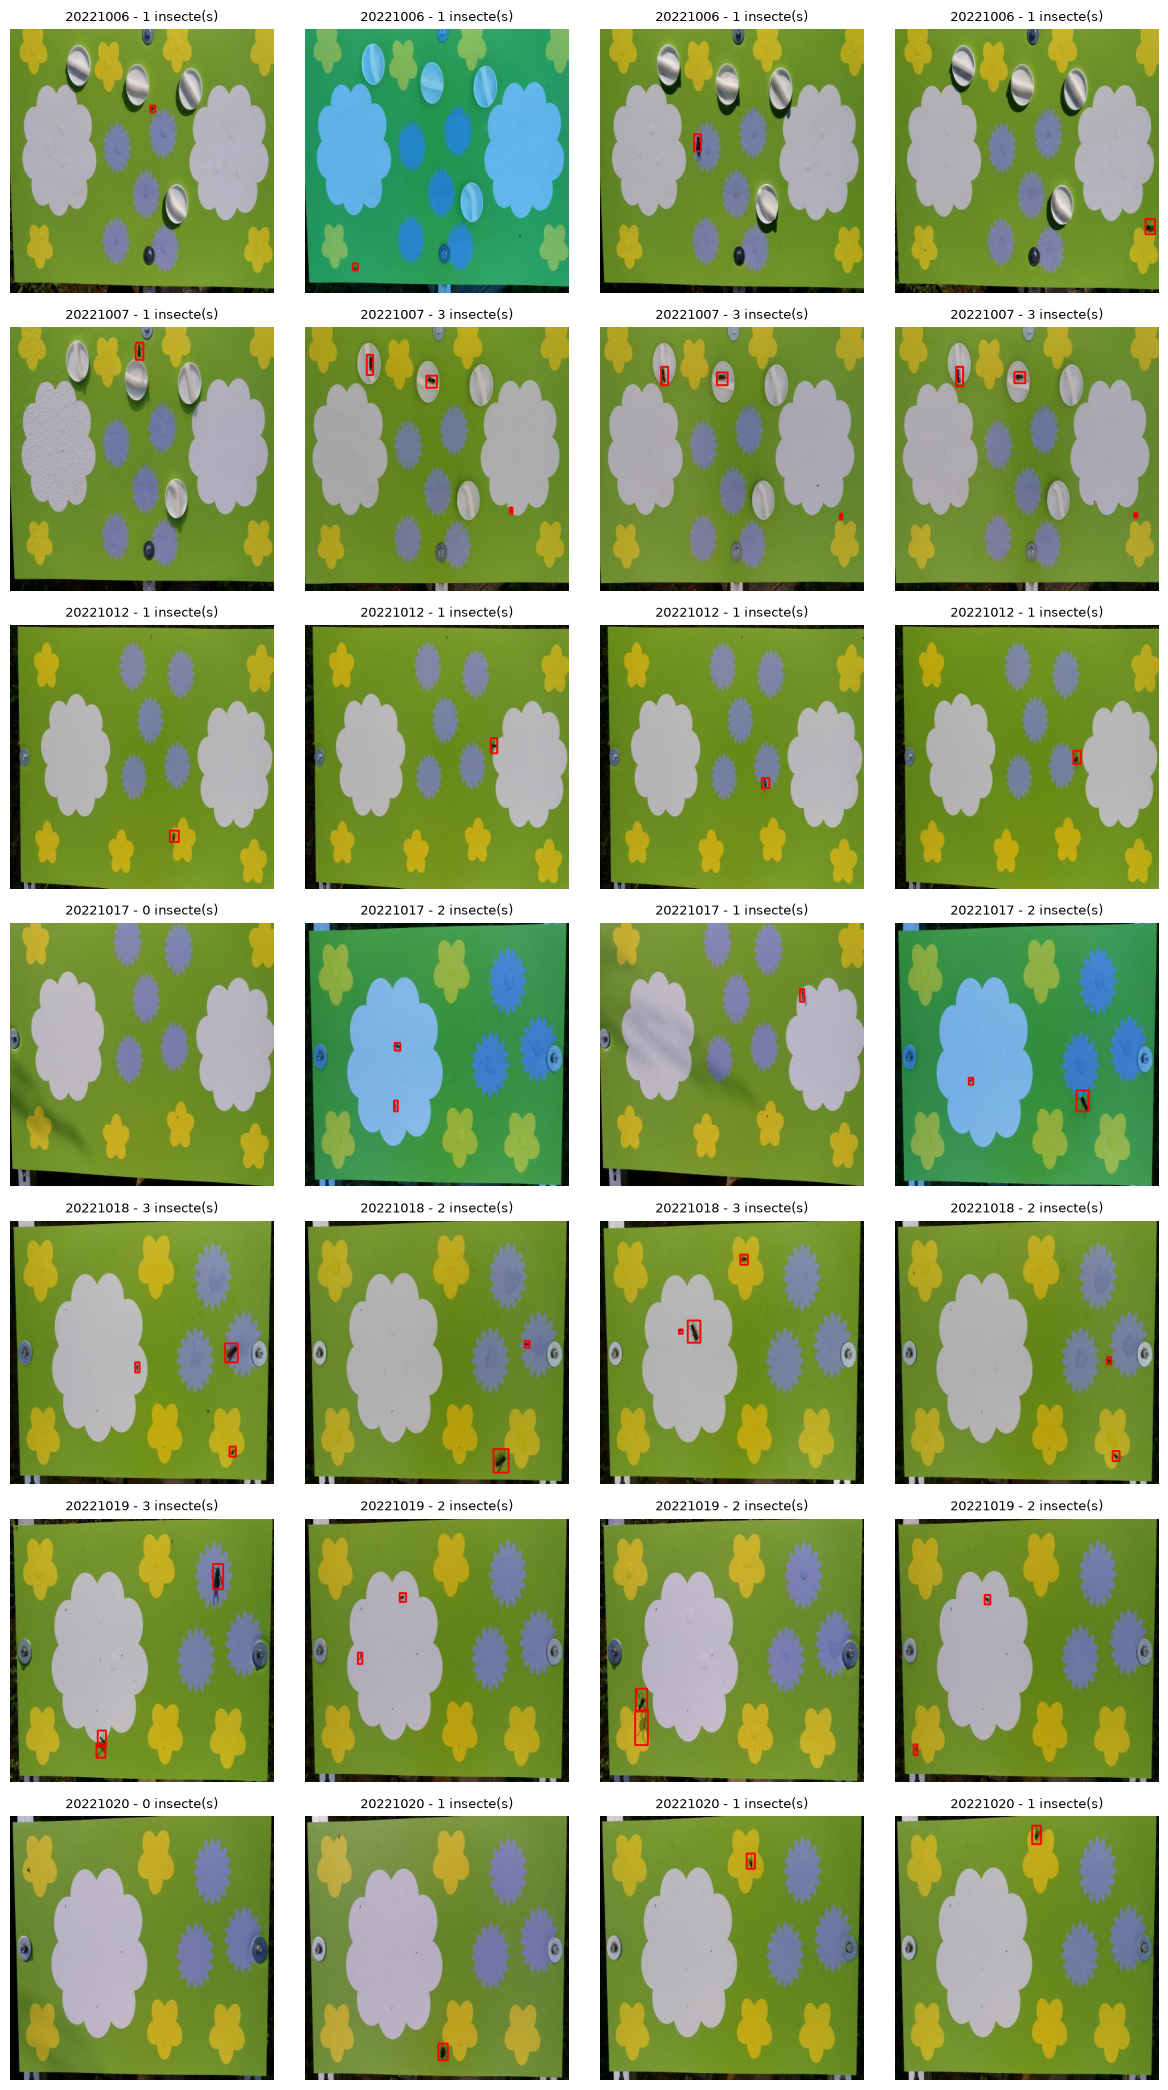

In [5]:
def dessiner(img_path, detections=()):
    """Image en RGB, vérité en rouge, détections éventuelles en vert."""
    image = cv2.imread(str(img_path))
    for (x1, y1, x2, y2) in lire_boites(img_path):
        cv2.rectangle(image, (x1, y1), (x2, y2), (0, 0, 255), 2)                          # rouge (en BGR)
    for (x1, y1, x2, y2) in detections:
        cv2.rectangle(image, (int(x1) - 2, int(y1) - 2), (int(x2) + 2, int(y2) + 2), (0, 255, 0), 1)
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)                                         # matplotlib attend du RGB

random.seed(1)
jours = sorted(journees_gardees)
fig, axes = plt.subplots(len(jours), 4, figsize=(12, 3 * len(jours)))
for i, jour in enumerate(jours):
    for k, img_path in enumerate(random.sample(journees_gardees[jour], 4)):
        axes[i, k].imshow(dessiner(img_path))
        axes[i, k].set_title(f"{jour} - {verite[img_path]} insecte(s)", fontsize=9)
        axes[i, k].axis("off")
plt.tight_layout()
plt.show()

Ce que je retiens :
- les insectes sont de petites taches sombres sur une plaque verte avec des fleurs jaunes, bleues et blanches ;
- beaucoup d'objets sombres ne sont pas des insectes : coupelles blanches et leurs ombres (06/10 et 07/10), vis et boutons, fond et végétation autour de la plaque ;
- la balance des blancs varie (certaines images du 17/10 tirent vers le bleu) ;
- le cadrage bouge d'une journée à l'autre, et même au cours d'une journée ;
- un insecte posé sur une fleur bleue est peu contrasté ;
- les images ont été étirées en 416 × 416 par Roboflow (« Stretch »), d'où des insectes qui paraissent allongés verticalement ;
- au sein d'une journée, beaucoup d'images se ressemblent presque à l'identique (photos à quelques secondes d'intervalle).

## 3. Protocole d'évaluation

Je fixe la façon de mesurer avant d'écrire la méthode, pour ne pas choisir après coup la mesure qui arrange.

Pour chaque image, l'erreur est `prédit − vrai`. Sur un ensemble d'images, je calcule :

| Mesure | Définition | Question |
|---|---|---|
| Exactitude | part des images où prédit = vrai | le compte est-il juste ? |
| MAE | moyenne de \|prédit − vrai\| | de combien d'insectes je me trompe en moyenne |
| Biais | moyenne de (prédit − vrai) | est-ce que je compte systématiquement trop (+) ou pas assez (−) |
| Exactitude à ±1 | part des images où \|prédit − vrai\| ≤ 1 | à un insecte près |

Le biais seul est trompeur, car des erreurs de +1 et −1 s'annulent : je le lis toujours avec la MAE.

Exemple calculé à la main : vrais = [1, 2, 0, 3], prédits = [1, 3, 0, 1], erreurs = [0, +1, 0, −2], d'où exactitude 0,50 ; MAE 0,75 ; biais −0,25 ; ±1 0,75.

In [6]:
def evaluer(vrais, predits):
    erreurs = [p - v for v, p in zip(vrais, predits)]
    n = len(erreurs)
    return {
        "exactitude": sum(1 for e in erreurs if e == 0) / n,
        "MAE":        sum(abs(e) for e in erreurs) / n,
        "biais":      sum(erreurs) / n,
        "exact_pm1":  sum(1 for e in erreurs if abs(e) <= 1) / n,
    }

print(evaluer([1, 2, 0, 3], [1, 3, 0, 1]))   # doit donner 0.5 / 0.75 / -0.25 / 0.75

{'exactitude': 0.5, 'MAE': 0.75, 'biais': -0.25, 'exact_pm1': 0.75}


### Référence naïve

Une méthode n'a d'intérêt que si elle fait mieux qu'une réponse qui ne regarde pas l'image. Première référence : répondre « 1 insecte » partout, le cas le plus fréquent.

Je donne toujours les résultats par journée en plus du global : les journées n'ont pas la même taille (386 images le 06/10, 66 le 20/10) et une moyenne globale peut masquer une journée ratée.

In [7]:
def afficher_resultats(predire_journee):
    """predire_journee(jour) renvoie la liste des comptes prédits pour les images de la journée."""
    tous_vrais, tous_predits = [], []
    print(f"{'journée':10} {'images':>6} {'exact.':>7} {'MAE':>6} {'biais':>6} {'±1':>6}")
    for jour in sorted(journees_gardees):
        vrais = [verite[img] for img in journees_gardees[jour]]
        predits = predire_journee(jour)
        r = evaluer(vrais, predits)
        print(f"{jour:10} {len(vrais):6} {r['exactitude']:7.2f} {r['MAE']:6.2f} {r['biais']:6.2f} {r['exact_pm1']:6.2f}")
        tous_vrais += vrais
        tous_predits += predits
    r = evaluer(tous_vrais, tous_predits)
    print(f"{'GLOBAL':10} {len(tous_vrais):6} {r['exactitude']:7.2f} {r['MAE']:6.2f} {r['biais']:6.2f} {r['exact_pm1']:6.2f}")

def toujours_un(jour):
    return [1] * len(journees_gardees[jour])

afficher_resultats(toujours_un)

journée    images  exact.    MAE  biais     ±1
20221006      386    0.55   0.65  -0.62   0.82
20221007      114    0.14   1.51  -1.44   0.46
20221012       95    0.89   0.11   0.00   1.00
20221017      107    0.35   0.74  -0.68   0.93
20221018      148    0.18   0.97  -0.97   0.86
20221019      185    0.35   1.09  -1.07   0.75
20221020       66    0.68   0.35  -0.20   0.97
GLOBAL       1101    0.44   0.80  -0.75   0.81


Sans regarder une seule image, on obtient 44 % d'exactitude et une MAE de 0,80. C'est le niveau à battre.

Les journées sont très différentes : 89 % d'exactitude le 12/10 (presque uniquement des images à un insecte), 14 % le 07/10. Le 12/10 illustre aussi le piège du biais : il vaut 0,00 alors que 11 % des réponses sont fausses, parce que les 5 images vides (+1) et les 5 images à deux insectes (−1) se compensent.

### Réglage et test sur des journées différentes

La méthode aura des paramètres (seuil, tailles). Les régler et les tester sur les mêmes images donnerait un score trop optimiste.

Je n'utilise pas le découpage train / valid / test de Roboflow : il est aléatoire, donc chaque journée se retrouve dans les trois parties. Deux photos d'une même journée prises à quelques secondes d'intervalle sont presque identiques ; régler sur l'une et tester sur l'autre revient à tester sur des images déjà vues (fuite de données).

J'utilise à la place une validation « une journée de côté » : je règle sur 6 journées, je teste sur la 7e, et je recommence 7 fois. Chaque journée est ainsi évaluée par une méthode qui ne l'a jamais vue, comme ce serait le cas sur une nouvelle journée de terrain.

Seconde référence, qui a un « réglage » : répondre partout la moyenne arrondie du nombre d'insectes des six autres journées.

In [7]:
def moyenne_des_autres_jours(jour_test):
    comptes_autres = [verite[img] for jour, imgs in journees_gardees.items() if jour != jour_test for img in imgs]
    reglage = round(sum(comptes_autres) / len(comptes_autres))   # appris sans la journée testée
    return [reglage] * len(journees_gardees[jour_test])

afficher_resultats(moyenne_des_autres_jours)

journée    images  exact.    MAE  biais     ±1
20221006      386    0.25   0.79   0.38   0.96
20221007      114    0.29   0.86  -0.44   0.85
20221012       95    0.05   1.00   1.00   0.95
20221017      107    0.55   0.49   0.32   0.96
20221018      148    0.68   0.32   0.03   0.99
20221019      185    0.39   0.81  -0.07   0.88
20221020       66    0.21   0.86   0.80   0.92
GLOBAL       1101    0.35   0.73   0.25   0.94


La moyenne des autres journées vaut 2 à chaque tour. Cette référence a une exactitude plus faible que « toujours 1 » (0,35 contre 0,44) mais une meilleure MAE (0,73 contre 0,80) : les mesures ne classent pas les méthodes de la même façon, c'est pourquoi je les garde toutes.

| Référence (sans regarder l'image) | Exactitude | MAE | Biais | ±1 |
|---|---|---|---|---|
| Toujours 1 | 0,44 | 0,80 | −0,75 | 0,81 |
| Moyenne des autres jours (= 2) | 0,35 | 0,73 | +0,25 | 0,94 |

## 4. Première méthode, sur une image

Hypothèse de départ : un insecte est une petite tache sombre sur une plaque claire. La méthode :
1. passer l'image en niveaux de gris ;
2. garder les pixels plus sombres qu'un seuil (masque binaire) ;
3. regrouper les pixels voisins en taches (composantes connexes) ;
4. éliminer les taches trop petites, trop grandes, ou qui touchent le bord ;
5. compter les taches restantes.

Je la construis d'abord sur une seule image du 18/10, avec deux insectes dont un minuscule, en regardant le résultat de chaque opération.

insecte en (123,171)-(129,179) : pixel le plus sombre = 19
insecte en (339,92)-(353,111) : pixel le plus sombre = 13
luminosité médiane de l'image : 121.0


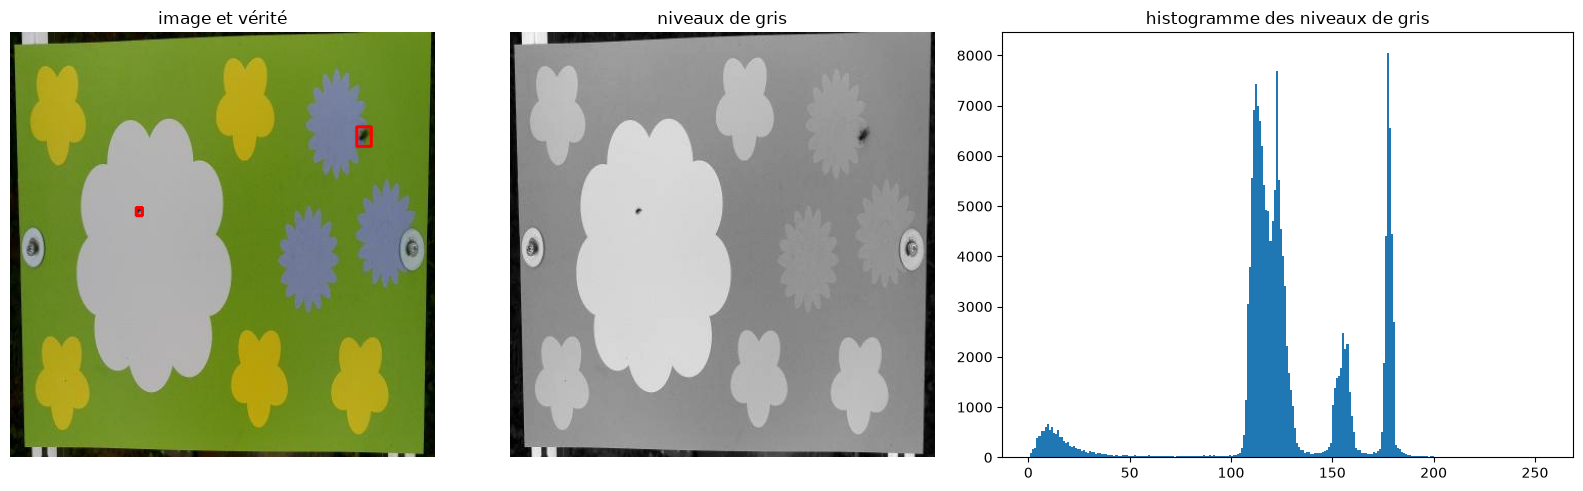

In [9]:
exemple = Path("train/images/20221018_09-16-13-939277_raw_jpg.rf.4decef9bb894f8e36b1094cebbecc99d.jpg")
gris = lire_gris(exemple)          # tableau 416 x 416, de 0 (noir) à 255 (blanc)

for (x1, y1, x2, y2) in lire_boites(exemple):
    print(f"insecte en ({x1},{y1})-({x2},{y2}) : pixel le plus sombre = {gris[y1:y2, x1:x2].min()}")
print("luminosité médiane de l'image :", np.median(gris))

fig, axes = plt.subplots(1, 3, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 1, 1.3]})
axes[0].imshow(dessiner(exemple)); axes[0].set_title("image et vérité"); axes[0].axis("off")
axes[1].imshow(gris, cmap="gray"); axes[1].set_title("niveaux de gris"); axes[1].axis("off")
axes[2].hist(gris.ravel(), bins=256, range=(0, 256)); axes[2].set_title("histogramme des niveaux de gris")
plt.tight_layout()
plt.show()

Les pixels les plus sombres des insectes valent 13 et 19, la plaque est autour de 121. Un seuil à 80 sépare bien les deux sur cette image. C'est un point de départ choisi sur une seule image, pas un réglage définitif.

`cv2.threshold(gris, 80, 255, cv2.THRESH_BINARY_INV)` met à 255 (blanc) les pixels ≤ 80 et à 0 les autres ; `INV` inverse le sens habituel, puisque je cherche le sombre. `cv2.connectedComponentsWithStats` regroupe ensuite les pixels blancs qui se touchent et donne pour chaque tache `[x, y, largeur, hauteur, aire]` (la tache 0 est le fond).

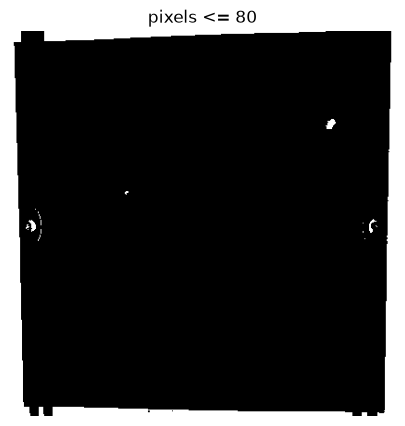

22 taches ; celles de 5 pixels ou plus :
 n°    x    y  larg  haut   aire
  1    0    0    22   416   4211
  2   37    0   304    11   1657
  3  397    0    19   416   3307
  4  341   95    11    11     75
  5  124  173     4     4     10
  8   31  198     2     5      5
  9  388  203     8    15     42
 10   20  204     8    13     53
 11   33  204     1     6      6
 13   17  209     4     5     10
 16   33  214     1     5      5
 18   30  220     3     7      7
 20   31  406     6    10     52
 21   46  406   324    10   2162
 22  380  412     6     4     24


In [10]:
_, masque = cv2.threshold(gris, 80, 255, cv2.THRESH_BINARY_INV)
n, _, stats, _ = cv2.connectedComponentsWithStats(masque)

plt.figure(figsize=(5, 5))
plt.imshow(masque, cmap="gray"); plt.title("pixels <= 80"); plt.axis("off")
plt.show()

print(n - 1, "taches ; celles de 5 pixels ou plus :")
print(f"{'n°':>3} {'x':>4} {'y':>4} {'larg':>5} {'haut':>5} {'aire':>6}")
for i in range(1, n):
    x, y, w, h, aire = stats[i]
    if aire >= 5:
        print(f"{i:3} {x:4} {y:4} {w:5} {h:5} {aire:6}")

En comparant aux boîtes rouges : la tache 4 (aire 75) est le gros insecte, la tache 5 (aire 10) le petit. Les taches 1, 2, 3 et 21 font des milliers de pixels et touchent le bord : c'est le fond noir derrière la plaque. Les taches vers x ≈ 20-30 et x ≈ 388, y ≈ 200, sont les vis.

Deux règles en découlent : garder les taches de 8 à 600 pixels, et éliminer celles qui touchent le bord de l'image.

compté : 5  vrai : 2


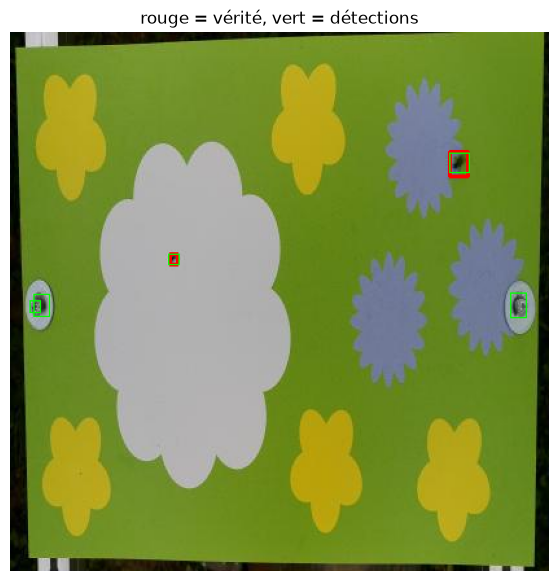

In [11]:
detections = []
for i in range(1, n):
    x, y, w, h, aire = stats[i]
    touche_bord = x == 0 or y == 0 or x + w == TAILLE or y + h == TAILLE
    if 8 <= aire <= 600 and not touche_bord:
        detections.append((x, y, x + w, y + h))

print("compté :", len(detections), " vrai :", verite[exemple])
plt.figure(figsize=(7, 7))
plt.imshow(dessiner(exemple, detections)); plt.title("rouge = vérité, vert = détections"); plt.axis("off")
plt.show()

Les deux insectes sont trouvés, y compris celui de 10 pixels, mais la méthode en compte 5 : les vis de gauche et de droite produisent 3 fausses détections. Elles sont sombres, de taille plausible et ne touchent pas le bord, donc les deux règles ne peuvent pas les écarter.

## 5. Passage à toutes les images

Je regroupe ces opérations dans une fonction, avec les mêmes réglages (seuil 80, aire de 8 à 600, bord exclu), et j'évalue avec la même fonction que les références.

`taches` renvoie toutes les taches sombres qui ne touchent pas le bord ; c'est la brique commune à toutes les variantes qui suivent.

In [12]:
def taches(gris, seuil, zone=None, sombres=True):
    """Taches qui ne touchent pas le bord : liste de (aire, boîte, centre).
    sombres=True : pixels <= seuil ; sombres=False : pixels > seuil.
    zone : masque optionnel, seules les taches dans la zone sont gardées."""
    type_seuil = cv2.THRESH_BINARY_INV if sombres else cv2.THRESH_BINARY
    _, masque = cv2.threshold(gris, seuil, 255, type_seuil)
    if zone is not None:
        masque = cv2.bitwise_and(masque, zone)
    n, _, stats, centres = cv2.connectedComponentsWithStats(masque)
    resultat = []
    for i in range(1, n):
        x, y, w, h, aire = stats[i]
        if not (x == 0 or y == 0 or x + w == TAILLE or y + h == TAILLE):
            resultat.append((aire, (x, y, x + w, y + h), tuple(centres[i])))
    return resultat

def detecter(img_path, seuil=80, aire_min=8, aire_max=600):
    return [boite for (aire, boite, centre) in taches(lire_gris(img_path), seuil) if aire_min <= aire <= aire_max]

print("image de la section 4 :", len(detecter(exemple)), "détections")   # doit redonner 5

debut = time.time()
detections_seuil = {img: detecter(img) for img in verite}
print(f"temps pour {len(verite)} images : {time.time() - debut:.1f} s\n")

afficher_resultats(lambda jour: [len(detections_seuil[img]) for img in journees_gardees[jour]])

image de la section 4 : 5 détections
temps pour 1101 images : 5.0 s

journée    images  exact.    MAE  biais     ±1
20221006      386    0.00   5.06   5.06   0.04
20221007      114    0.01   4.81   4.81   0.02
20221012       95    0.74   0.36   0.29   0.93
20221017      107    0.11   3.51   3.44   0.20
20221018      148    0.00   5.00   5.00   0.01
20221019      185    0.02   3.59   3.56   0.13
20221020       66    0.00   4.42   4.42   0.02
GLOBAL       1101    0.08   4.19   4.17   0.14


| Méthode | Exactitude | MAE | Biais | ±1 |
|---|---|---|---|---|
| Toujours 1 | 0,44 | 0,80 | −0,75 | 0,81 |
| Seuil simple | 0,08 | 4,19 | +4,17 | 0,14 |

La méthode fait bien pire que la référence naïve. Le biais est presque égal à la MAE : presque toutes les erreurs vont dans le même sens, la méthode compte trop. Le problème principal est donc les fausses détections, pas les insectes manqués. Seul le 12/10 s'en sort à peu près. Le calcul est rapide (quelques secondes pour 1 101 images).

Pour savoir quelles sont ces fausses détections, je regarde les pires erreurs, puis une image au hasard par journée.

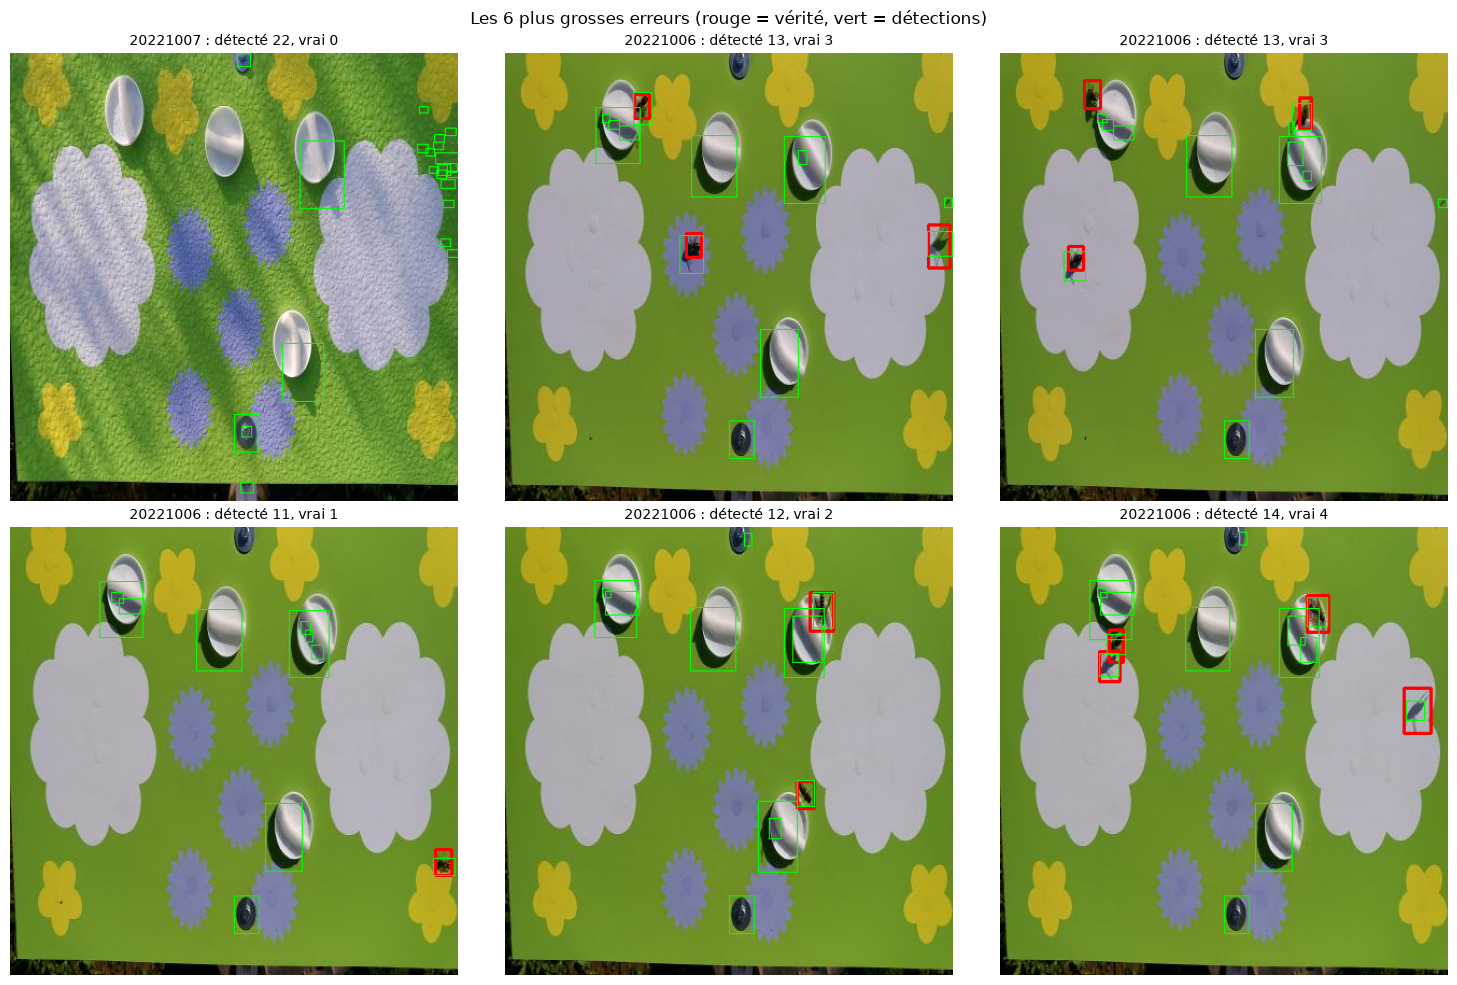

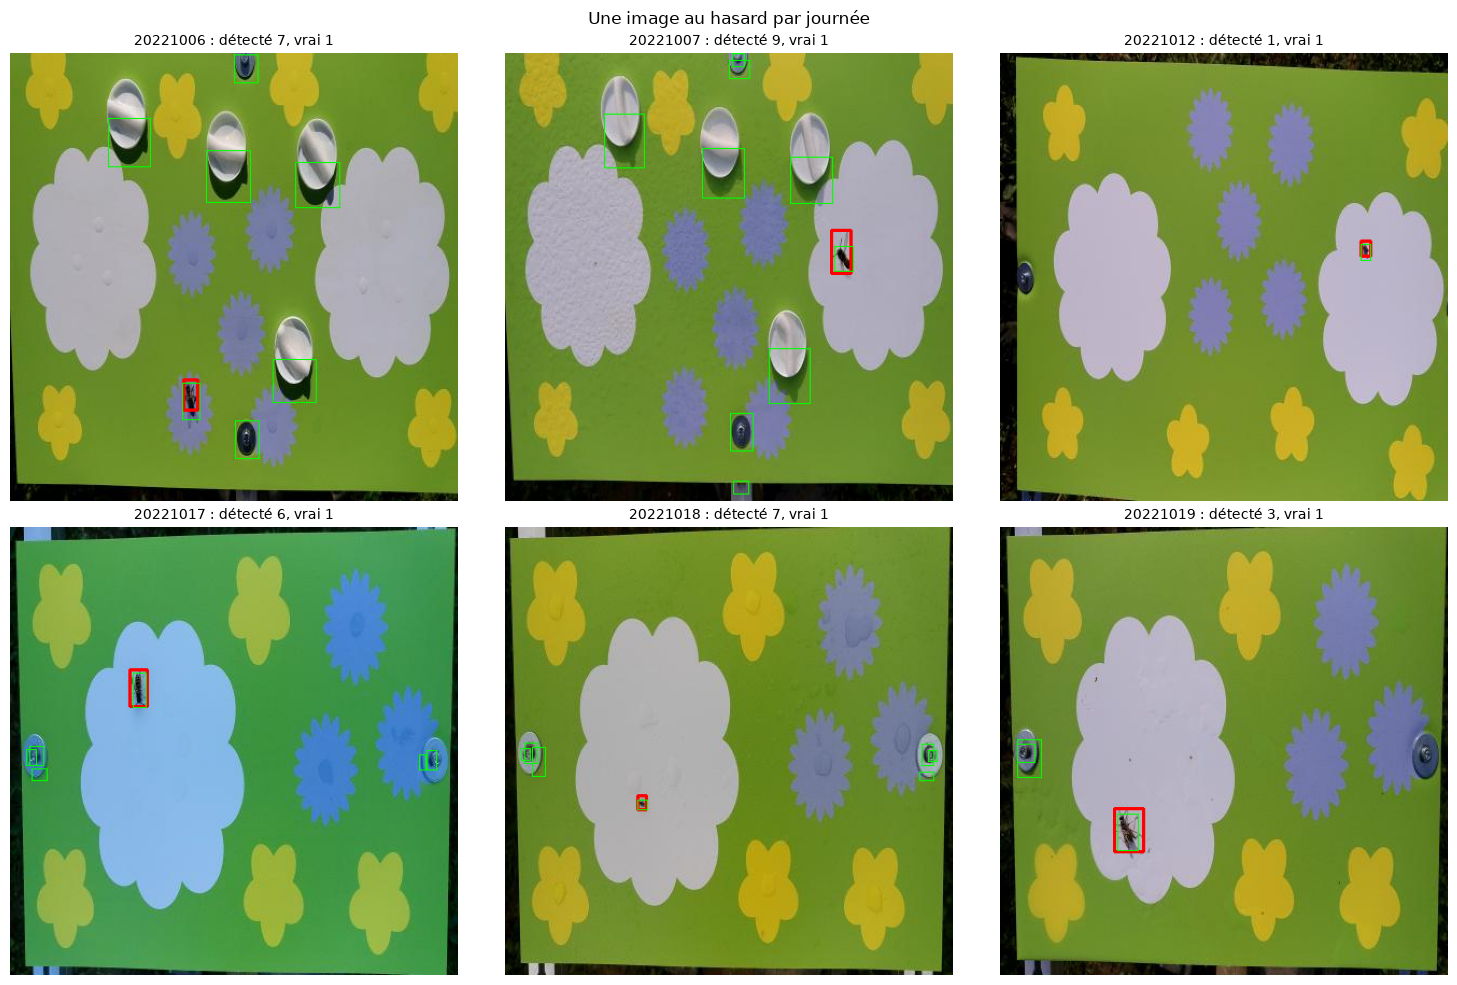

In [13]:
def montrer(liste_images, detections, titre):
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    for ax, img_path in zip(axes.ravel(), liste_images):
        ax.imshow(dessiner(img_path, detections[img_path]))
        ax.set_title(f"{img_path.name[:8]} : détecté {len(detections[img_path])}, vrai {verite[img_path]}", fontsize=10)
        ax.axis("off")
    fig.suptitle(titre)
    plt.tight_layout()
    plt.show()

pires = sorted(verite, key=lambda img: abs(len(detections_seuil[img]) - verite[img]), reverse=True)
montrer(pires[:6], detections_seuil, "Les 6 plus grosses erreurs (rouge = vérité, vert = détections)")

random.seed(2)
quelques = [random.choice(journees_gardees[j]) for j in sorted(journees_gardees)]
montrer(quelques[:6], detections_seuil, "Une image au hasard par journée")

Les fausses détections se rangent en quatre catégories :

| Fausse détection | Où |
|---|---|
| ombres des coupelles blanches | 06/10 et 07/10 |
| vis et boutons sombres | toutes les journées |
| végétation ou pied hors de la plaque | bords de l'image |
| ombres d'arbres sur la plaque | 07/10 (22 détections pour 0 insecte sur la pire image) |

Le 12/10 fonctionne mieux parce que, avec ce cadrage, la vis touche le bord de l'image et la règle du bord l'élimine : c'est un hasard, pas une qualité de la méthode.

Quelques insectes sont aussi manqués : ceux qui sont clairs ou posés sur une fleur bleue, pas assez sombres pour passer sous le seuil.

## 6. Améliorations testées

Je change une seule chose à la fois et je mesure. Une idée qui n'améliore pas les chiffres est abandonnée, mais notée.

### 6.1 Ne garder que la plaque

La plaque est la plus grande zone claire de l'image. Pour obtenir son masque : seuil à 70 pour garder les pixels clairs, plus grande composante, remplissage de son contour extérieur (les insectes et les vis y font des trous), puis érosion de quelques pixels pour retirer la bordure. Les autres réglages restent ceux de la section 5.

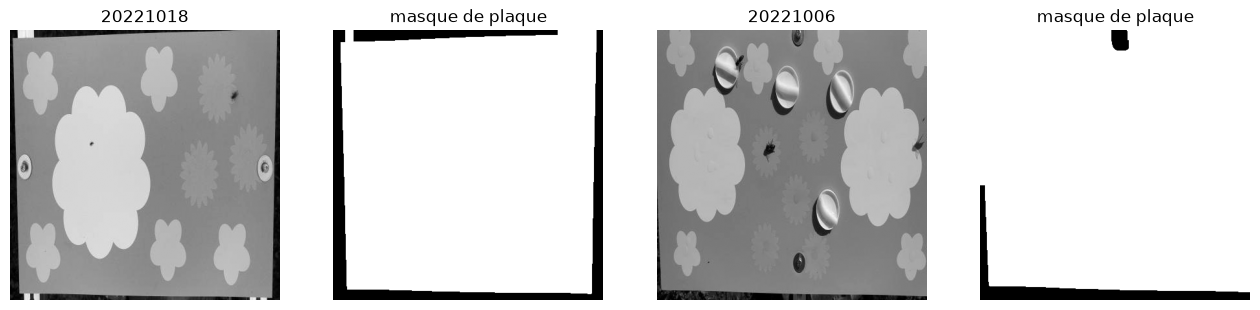

journée    images  exact.    MAE  biais     ±1
20221006      386    0.00   5.17   5.17   0.04
20221007      114    0.00   4.96   4.96   0.01
20221012       95    0.74   0.38   0.32   0.93
20221017      107    0.08   3.56   3.50   0.17
20221018      148    0.00   4.96   4.96   0.01
20221019      185    0.03   3.58   3.57   0.13
20221020       66    0.00   4.41   4.41   0.02
GLOBAL       1101    0.08   4.24   4.23   0.14


In [14]:
def masque_plaque(gris, seuil=70, erosion=6):
    _, clair = cv2.threshold(gris, seuil, 255, cv2.THRESH_BINARY)
    n, etiquettes, stats, _ = cv2.connectedComponentsWithStats(clair)
    plus_grande = 1 + np.argmax(stats[1:, 4])                  # stats[1:, 4] : aires de toutes les taches sauf le fond
    plaque = np.where(etiquettes == plus_grande, 255, 0).astype(np.uint8)
    contours, _ = cv2.findContours(plaque, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    plaque = np.zeros_like(plaque)
    cv2.drawContours(plaque, contours, -1, 255, thickness=-1)  # contour extérieur rempli : les trous sont bouchés
    return cv2.erode(plaque, np.ones((3, 3), np.uint8), iterations=erosion)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for k, img_path in enumerate([exemple, pires[1]]):
    g = lire_gris(img_path)
    axes[2*k].imshow(g, cmap="gray"); axes[2*k].set_title(img_path.name[:8])
    axes[2*k+1].imshow(masque_plaque(g), cmap="gray"); axes[2*k+1].set_title("masque de plaque")
for ax in axes: ax.axis("off")
plt.show()

comptes_plaque = {}
for img in verite:
    g = lire_gris(img)
    comptes_plaque[img] = sum(1 for (aire, _, _) in taches(g, 80, zone=masque_plaque(g)) if 8 <= aire <= 600)
afficher_resultats(lambda jour: [comptes_plaque[img] for img in journees_gardees[jour]])

Le masque trouve bien la plaque, mais le score ne bouge pas (MAE 4,24 contre 4,19). Les fausses détections sont sur la plaque (ombres, vis) ; ce qui était en dehors touchait déjà le bord de l'image et était déjà éliminé. Idée abandonnée.

### 6.2 Un filtre de taille plus strict

Avant de choisir des valeurs, je compare l'aire des taches qui tombent sur un insecte annoté (centre dans une boîte rouge) à celle des fausses détections. Je calcule ici, une fois pour toutes, les taches de chaque image pour plusieurs seuils ; ce cache sert à toute la suite de la section.

cache calculé en 9 s
taches sur un insecte : 1694   fausses détections : 4823


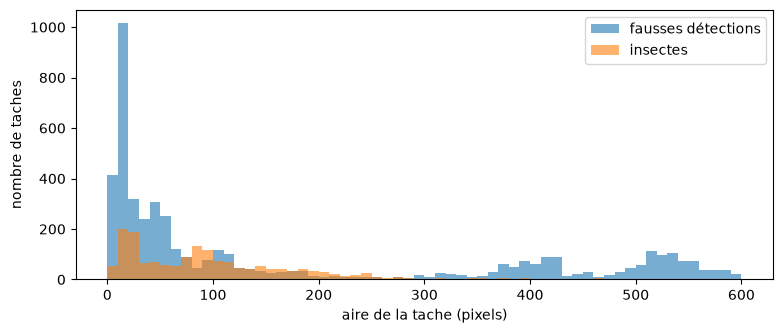

aire >= 20 : on garde 85% des insectes et 70% des fausses détections
aire >= 40 : on garde 70% des insectes et 59% des fausses détections
aire >= 60 : on garde 63% des insectes et 47% des fausses détections


In [15]:
SEUILS = [40, 50, 60, 70, 80, 90]
debut = time.time()
cache_taches = {s: {} for s in SEUILS}
for img in verite:
    g = lire_gris(img)
    for s in SEUILS:
        cache_taches[s][img] = taches(g, s)
print(f"cache calculé en {time.time() - debut:.0f} s")

def dans_une_boite(centre, boites):
    cx, cy = centre
    return any(x1 <= cx <= x2 and y1 <= cy <= y2 for (x1, y1, x2, y2) in boites)

aires_vraies, aires_fausses = [], []
for img in verite:
    boites = lire_boites(img)
    for (aire, _, centre) in cache_taches[80][img]:
        if 8 <= aire <= 600:
            (aires_vraies if dans_une_boite(centre, boites) else aires_fausses).append(aire)

print("taches sur un insecte :", len(aires_vraies), "  fausses détections :", len(aires_fausses))
plt.figure(figsize=(9, 3.5))
plt.hist(aires_fausses, bins=60, range=(0, 600), alpha=0.6, label="fausses détections")
plt.hist(aires_vraies, bins=60, range=(0, 600), alpha=0.6, label="insectes")
plt.xlabel("aire de la tache (pixels)"); plt.ylabel("nombre de taches"); plt.legend()
plt.show()

for aire_min in [20, 40, 60]:
    v = sum(1 for a in aires_vraies if a >= aire_min) / len(aires_vraies)
    f = sum(1 for a in aires_fausses if a >= aire_min) / len(aires_fausses)
    print(f"aire >= {aire_min} : on garde {v:.0%} des insectes et {f:.0%} des fausses détections")

Il y a presque trois fausses détections pour une vraie, et les deux distributions se chevauchent largement. Relever l'aire minimale élimine des fausses détections, mais aussi des insectes, presque au même rythme (à 40 pixels : 70 % des insectes gardés contre 59 % des fausses détections). La taille est un critère faible ; elle peut réduire l'erreur de comptage, sans plus.

### 6.3 Réglage par validation « une journée de côté »

Trois paramètres : seuil, aire minimale, aire maximale. Pour chaque journée testée, j'essaie toutes les combinaisons d'une grille sur les six autres journées, je garde celle qui a la plus petite MAE, et je l'applique à la journée testée.

In [16]:
def compter(img, seuil, aire_min, aire_max):
    return sum(1 for (aire, _, _) in cache_taches[seuil][img] if aire_min <= aire <= aire_max)

def regler(jours, seuils, aires_min, aires_max):
    """Combinaison de la grille qui a la plus petite MAE sur ces journées."""
    images = [img for j in jours for img in journees_gardees[j]]
    vrais = [verite[img] for img in images]
    meilleur, meilleure_mae = None, None
    for s in seuils:
        for a_min in aires_min:
            for a_max in aires_max:
                mae = evaluer(vrais, [compter(img, s, a_min, a_max) for img in images])["MAE"]
                if meilleure_mae is None or mae < meilleure_mae:
                    meilleur, meilleure_mae = (s, a_min, a_max), mae
    return meilleur

PETITE_GRILLE = ([40, 50, 60, 70, 80], [5, 10, 20, 30, 40], [150, 300, 600])   # 75 combinaisons
GRILLE = PETITE_GRILLE

def methode_reglee(jour_test, afficher=True):
    autres = [j for j in journees_gardees if j != jour_test]
    s, a_min, a_max = regler(autres, *GRILLE)
    if afficher:
        print(f"  ({jour_test} : réglage choisi sur les autres journées = seuil {s}, aire {a_min}-{a_max})")
    return [compter(img, s, a_min, a_max) for img in journees_gardees[jour_test]]

afficher_resultats(methode_reglee)

journée    images  exact.    MAE  biais     ±1
  (20221006 : réglage choisi sur les autres journées = seuil 70, aire 40-150)
20221006      386    0.49   0.62  -0.26   0.90
  (20221007 : réglage choisi sur les autres journées = seuil 70, aire 40-300)
20221007      114    0.23   1.17   0.22   0.83
  (20221012 : réglage choisi sur les autres journées = seuil 70, aire 40-150)
20221012       95    0.55   0.46  -0.42   0.99
  (20221017 : réglage choisi sur les autres journées = seuil 70, aire 40-150)
20221017      107    0.35   0.93  -0.71   0.76
  (20221018 : réglage choisi sur les autres journées = seuil 70, aire 40-150)
20221018      148    0.36   0.83  -0.71   0.83
  (20221019 : réglage choisi sur les autres journées = seuil 70, aire 40-300)
20221019      185    0.31   1.15   0.74   0.69
  (20221020 : réglage choisi sur les autres journées = seuil 70, aire 30-150)
20221020       66    0.03   1.94   1.91   0.24
GLOBAL       1101    0.38   0.89  -0.03   0.80


Le réglage choisi est presque toujours le même (seuil 70, aire de 40 à 150), ce qui indique qu'il est stable d'une journée à l'autre.

Résultat global : exactitude 0,38, MAE 0,89, biais −0,03, ±1 0,80. C'est un net progrès par rapport à la section 5 (MAE 4,19), mais pas mieux que « toujours 1 » (0,80). Le biais quasi nul est le seul point fort apparent. Le 20/10 est raté (biais +1,91), ce que le global ne montre pas.

Deux vérifications : que se passe-t-il avec une grille plus large, et que se serait-il passé si j'avais réglé et testé sur toutes les journées ?

In [17]:
GRANDE_GRILLE = ([50, 60, 70, 80, 90], [10, 20, 30, 40, 50, 60, 80], [100, 150, 200, 300, 600])

print("Grande grille, une journée de côté")
GRILLE = GRANDE_GRILLE
afficher_resultats(lambda jour: methode_reglee(jour, afficher=False))
GRILLE = PETITE_GRILLE

print("\nRéglé et testé sur toutes les journées (score optimiste)")
for nom, grille in [("petite", PETITE_GRILLE), ("grande", GRANDE_GRILLE)]:
    reglage = regler(list(journees_gardees), *grille)
    r = evaluer(list(verite.values()), [compter(img, *reglage) for img in verite])
    print(f"{nom:7} grille, réglage {reglage} : exact. {r['exactitude']:.2f}  MAE {r['MAE']:.2f}  "
          f"biais {r['biais']:.2f}  ±1 {r['exact_pm1']:.2f}")

Grande grille, une journée de côté
journée    images  exact.    MAE  biais     ±1
20221006      386    0.31   1.02   0.63   0.76
20221007      114    0.25   1.00  -0.16   0.87
20221012       95    0.55   0.46  -0.42   0.99
20221017      107    0.39   0.88  -0.65   0.77
20221018      148    0.36   0.77  -0.64   0.87
20221019      185    0.35   1.06   0.44   0.69
20221020       66    0.06   1.41   1.17   0.55
GLOBAL       1101    0.33   0.95   0.16   0.78

Réglé et testé sur toutes les journées (score optimiste)
petite  grille, réglage (70, 40, 150) : exact. 0.39  MAE 0.82  biais -0.23  ±1 0.83
grande  grille, réglage (70, 40, 200) : exact. 0.40  MAE 0.80  biais -0.06  ±1 0.84


| Réglage | Grille | Exactitude | MAE | Biais | ±1 |
|---|---|---|---|---|---|
| une journée de côté | petite | 0,38 | 0,89 | −0,03 | 0,80 |
| une journée de côté | grande | 0,33 | 0,95 | +0,16 | 0,78 |
| sur toutes les journées | petite | 0,39 | 0,82 | −0,23 | 0,83 |
| sur toutes les journées | grande | 0,40 | 0,80 | −0,06 | 0,84 |

Régler et tester sur les mêmes images aurait donné une MAE de 0,80, soit « aussi bien que la référence », ce qui est faux sur une journée nouvelle. Et la grande grille, meilleure en apparence dans ce cas, est moins bonne en validation honnête (0,95 contre 0,89) : avec plus de combinaisons, on trouve plus facilement un réglage qui colle aux journées de réglage sans se généraliser (sur-ajustement). Je garde la petite grille.

### 6.4 Ce que la méthode détecte vraiment

Un bon compte ne garantit pas de bonnes détections : on peut compter 2 en manquant les 2 insectes et en détectant 2 vis. J'apparie donc les détections aux boîtes annotées (une détection dont le centre tombe dans une boîte libre est un vrai positif, VP ; sinon c'est une fausse détection, FP ; une boîte jamais touchée est un insecte manqué, FN), et je calcule :
- la précision VP / (VP + FP) : quand la méthode dit « insecte », a-t-elle raison ?
- le rappel VP / (VP + FN) : quelle part des insectes trouve-t-elle ?

In [29]:
def apparier(img, seuil, aire_min, aire_max):
    """Pour une image : (nombre de détections, VP, FP, FN)."""
    boites = lire_boites(img)
    trouvees, k, vp, fp = set(), 0, 0, 0
    for (aire, _, (cx, cy)) in cache_taches[seuil][img]:
        if not (aire_min <= aire <= aire_max):
            continue
        k += 1
        libres = [i for i, (x1, y1, x2, y2) in enumerate(boites)
                  if i not in trouvees and x1 <= cx <= x2 and y1 <= cy <= y2]
        if libres:
            trouvees.add(libres[0])      # une boîte ne peut être trouvée qu'une fois
            vp += 1
        else:
            fp += 1
    return k, vp, fp, len(boites) - len(trouvees)

def precision_rappel(seuil, aire_min, aire_max):
    vp = fp = fn = 0
    for img in verite:
        _, a, b, c = apparier(img, seuil, aire_min, aire_max)
        vp, fp, fn = vp + a, fp + b, fn + c
    print(f"seuil {seuil}, aire {aire_min}-{aire_max} : VP {vp}, FP {fp}, FN {fn}, "
          f"précision {vp / (vp + fp):.2f}, rappel {vp / (vp + fn):.2f}")

precision_rappel(80, 8, 600)    # section 5
precision_rappel(70, 40, 150)   # réglage le plus souvent choisi en 6.3

seuil 80, aire 8-600 : VP 1653, FP 4864, FN 278, précision 0.25, rappel 0.86
seuil 70, aire 40-150 : VP 884, FP 798, FN 1047, précision 0.53, rappel 0.46


Avec le réglage retenu, la méthode ne trouve qu'environ la moitié des insectes (rappel 0,46) et une détection sur deux est fausse (précision 0,53). Le biais quasi nul vient d'une compensation : 1 047 insectes manqués contre 798 fausses détections. Le réglage a appris à jeter beaucoup d'insectes pour jeter aussi beaucoup de fausses détections.

C'est le résultat le plus important de cette section. Une méthode qui compte juste en moyenne pour de mauvaises raisons est fragile : si les conditions changent (plus de vis, moins d'ombres), l'équilibre se rompt et le biais revient. Les mesures de comptage seules ne permettaient pas de le voir.

### 6.5 Soustraction de fond et black-hat

Deux méthodes classiques, qui produisent toutes deux une image où les candidats insectes sont clairs, suivie du même schéma seuil, taches, filtre :
- **soustraction de fond** : le fond d'une journée est la médiane, pixel par pixel, de toutes ses images (un insecte n'est presque jamais au même endroit sur plus de la moitié des images) ; on garde ce qui est plus sombre que ce fond ;
- **black-hat** : opération morphologique qui fait ressortir les petites taches plus sombres que leur voisinage (ici, plus petites qu'un disque de 15 pixels), indépendamment de la luminosité globale.

Pour leur laisser toutes leurs chances, je les règle sur toutes les images (le cas favorable de 6.3, où le seuil simple obtient 0,82).

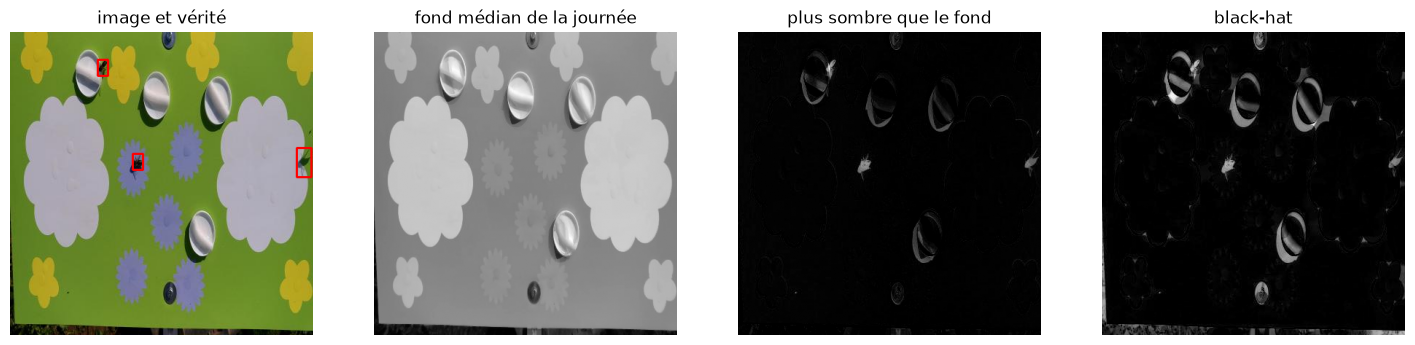

soustraction de fond   meilleur réglage (80, 60, 150) : exact. 0.26  MAE 1.13  biais -0.67  ±1 0.72
black-hat              meilleur réglage (120, 20, 150) : exact. 0.28  MAE 1.08  biais -0.69  ±1 0.74
temps : 24 s


In [18]:
debut = time.time()
fonds = {jour: np.median(np.stack([lire_gris(img) for img in imgs]), axis=0).astype(np.uint8)
         for jour, imgs in journees_gardees.items()}
noyau = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))

def image_fond(img_path):
    return cv2.subtract(fonds[img_path.name[:8]], lire_gris(img_path))     # valeurs négatives ramenées à 0

def image_blackhat(img_path):
    return cv2.morphologyEx(lire_gris(img_path), cv2.MORPH_BLACKHAT, noyau)

img_test = pires[1]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
axes[0].imshow(dessiner(img_test)); axes[0].set_title("image et vérité")
axes[1].imshow(fonds[img_test.name[:8]], cmap="gray"); axes[1].set_title("fond médian de la journée")
axes[2].imshow(image_fond(img_test), cmap="gray"); axes[2].set_title("plus sombre que le fond")
axes[3].imshow(image_blackhat(img_test), cmap="gray"); axes[3].set_title("black-hat")
for ax in axes: ax.axis("off")
plt.show()

vrais = list(verite.values())
for nom, transformer in [("soustraction de fond", image_fond), ("black-hat", image_blackhat)]:
    images_t = {img: transformer(img) for img in verite}
    # ici les candidats sont clairs : sombres=False
    aires = {s: {img: [a for (a, _, _) in taches(images_t[img], s, sombres=False)] for img in verite}
             for s in [40, 60, 80, 100, 120]}
    meilleur = None
    for s in aires:
        for a_min in [10, 20, 40, 60]:
            for a_max in [150, 300, 600]:
                r = evaluer(vrais, [sum(1 for a in aires[s][img] if a_min <= a <= a_max) for img in verite])
                if meilleur is None or r["MAE"] < meilleur[1]["MAE"]:
                    meilleur = ((s, a_min, a_max), r)
    (reglage, r) = meilleur
    print(f"{nom:22} meilleur réglage {reglage} : exact. {r['exactitude']:.2f}  MAE {r['MAE']:.2f}  "
          f"biais {r['biais']:.2f}  ±1 {r['exact_pm1']:.2f}")
print(f"temps : {time.time() - debut:.0f} s")

Le fond médian est flou autour des coupelles et des bords des fleurs : la plaque bouge au cours de la journée, les contours ne se superposent pas et ressortent comme des zones sombres. Le black-hat fait ressortir les insectes, mais aussi tous les petits détails sombres (bords des coupelles, vis, ombres).

Même réglées sur toutes les images, les deux méthodes font moins bien (MAE 1,13 et 1,08) que le seuil simple réglé de la même façon (0,82). Je les abandonne. La soustraction de fond serait probablement la bonne approche avec une caméra et une plaque fixes ; c'est une recommandation pour l'acquisition (section 8).

### 6.6 Comparaison à la référence, journée par journée

L'écart global (0,89 contre 0,80) mérite deux vérifications : le 06/10 représente 35 % des images et pèse lourd dans le global, et avec seulement 7 journées un petit écart peut être dû au hasard. Je compare donc les deux méthodes journée par journée, et je calcule la moyenne des MAE où chaque journée compte autant.

In [26]:
print(f"{'journée':10} {'MAE méthode':>12} {'MAE toujours 1':>15}   meilleure")
maes_methode, maes_ref = [], []
for jour in sorted(journees_gardees):
    vrais_jour = [verite[img] for img in journees_gardees[jour]]
    maes_methode.append(evaluer(vrais_jour, methode_reglee(jour, afficher=False))["MAE"])
    maes_ref.append(evaluer(vrais_jour, toujours_un(jour))["MAE"])
    print(f"{jour:10} {maes_methode[-1]:12.2f} {maes_ref[-1]:15.2f}   {'méthode' if maes_methode[-1] < maes_ref[-1] else 'référence'}")

victoires = sum(1 for m, r in zip(maes_methode, maes_ref) if m < r)
print(f"\nla méthode fait mieux sur {victoires} journées sur {len(maes_methode)}")
print(f"MAE moyenne des journées : méthode {np.mean(maes_methode):.2f}, toujours 1 {np.mean(maes_ref):.2f}")

journée     MAE méthode  MAE toujours 1   meilleure
20221006           0.62            0.65   méthode
20221007           1.17            1.51   méthode
20221012           0.46            0.11   référence
20221017           0.93            0.74   référence
20221018           0.83            0.97   méthode
20221019           1.15            1.09   référence
20221020           1.94            0.35   référence

la méthode fait mieux sur 3 journées sur 7
MAE moyenne des journées : méthode 1.02, toujours 1 0.77


La méthode fait mieux que « toujours 1 » sur 3 journées sur 7, moins bien sur 4, dont deux nettement (12/10 : 0,46 contre 0,11 ; 20/10 : 1,94 contre 0,35). En donnant le même poids à chaque journée, l'écart se creuse (1,02 contre 0,77). La conclusion juste est donc : pas de différence nette avec la référence, et nettement moins bien sur certaines journées.

### Bilan de la section 6

| Méthode (validation une journée de côté) | Exactitude | MAE globale | MAE moyenne des journées | Biais | ±1 |
|---|---|---|---|---|---|
| Toujours 1 | 0,44 | 0,80 | 0,77 | −0,75 | 0,81 |
| Moyenne des autres jours (= 2) | 0,35 | 0,73 | | +0,25 | 0,94 |
| Seuil simple (section 5) | 0,08 | 4,19 | | +4,17 | 0,14 |
| **Seuil et taille réglés (retenue)** | **0,38** | **0,89** | **1,02** | **−0,03** | **0,80** |

Essayé et abandonné : masque de plaque (sans effet), grille plus large (sur-ajustement), soustraction de fond et black-hat (moins bons même dans le cas favorable).

Le résultat est modeste et je sais pourquoi : ombres et vis ressemblent trop aux insectes en luminosité et en taille, et la plaque bouge trop pour utiliser un fond.

## 7. Ce que les résultats valent pour un biologiste

Un biologiste ne s'intéresse pas à une photo isolée. Je suppose ici que sa question est du type « y a-t-il plus d'insectes tel jour, ou avec telle odeur, que tel autre ? ». La grandeur utile est alors le nombre moyen d'insectes par image sur une période (par image, car les journées n'ont pas le même nombre de photos).

Des erreurs par image peuvent se compenser dans une moyenne, à condition de se compenser de la même façon chaque jour. Je le vérifie avec les prédictions de la méthode retenue, obtenues en validation une journée de côté.

Limite à garder en tête : on compte des insectes par image, pas des individus. Un insecte immobile pendant dix photos est compté dix fois.

journée    images total vrai total prédit   écart   insectes/image vrai  prédit
20221006      386        624          522    -16%                  1.62    1.35
20221007      114        278          303     +9%                  2.44    2.66
20221012       95         95           55    -42%                  1.00    0.58
20221017      107        180          104    -42%                  1.68    0.97
20221018      148        292          187    -36%                  1.97    1.26
20221019      185        383          520    +36%                  2.07    2.81
20221020       66         79          205   +159%                  1.20    3.11

classement réel   : ['20221007', '20221019', '20221018', '20221017', '20221006', '20221020', '20221012']
classement prédit : ['20221020', '20221019', '20221007', '20221006', '20221018', '20221017', '20221012']


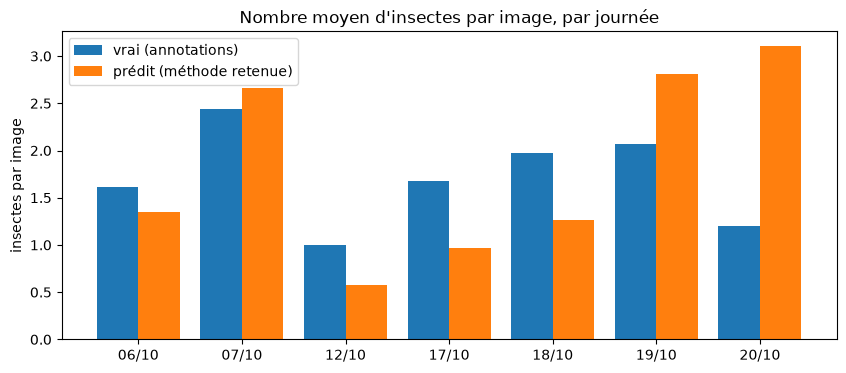

In [25]:
predictions_finales = {}
for jour in sorted(journees_gardees):
    for img, compte in zip(journees_gardees[jour], methode_reglee(jour, afficher=False)):
        predictions_finales[img] = compte

print(f"{'journée':10} {'images':>6} {'total vrai':>10} {'total prédit':>12} {'écart':>7}   {'insectes/image vrai':>19} {'prédit':>7}")
densite_vraie, densite_predite = {}, {}
for jour in sorted(journees_gardees):
    imgs = journees_gardees[jour]
    total_vrai = sum(verite[img] for img in imgs)
    total_pred = sum(predictions_finales[img] for img in imgs)
    densite_vraie[jour] = total_vrai / len(imgs)
    densite_predite[jour] = total_pred / len(imgs)
    print(f"{jour:10} {len(imgs):6} {total_vrai:10} {total_pred:12} {(total_pred - total_vrai) / total_vrai:+7.0%}   "
          f"{densite_vraie[jour]:19.2f} {densite_predite[jour]:7.2f}")

print("\nclassement réel   :", sorted(densite_vraie, key=densite_vraie.get, reverse=True))
print("classement prédit :", sorted(densite_predite, key=densite_predite.get, reverse=True))

jours = sorted(journees_gardees)
x = np.arange(len(jours))
plt.figure(figsize=(10, 4))
plt.bar(x - 0.2, [densite_vraie[j] for j in jours], width=0.4, label="vrai (annotations)")
plt.bar(x + 0.2, [densite_predite[j] for j in jours], width=0.4, label="prédit (méthode retenue)")
plt.xticks(x, [j[6:8] + "/" + j[4:6] for j in jours])
plt.ylabel("insectes par image"); plt.legend()
plt.title("Nombre moyen d'insectes par image, par journée")
plt.show()

Le biais global était quasi nul, mais par journée le total est faux de −42 % à +159 % : les erreurs se compensent entre journées, pas à l'intérieur de chacune.

Le classement des journées est faux : le 20/10, l'une des journées les moins fréquentées (1,20 insecte par image), est prédit comme la plus fréquentée (3,11). Les vraies différences entre journées (de 1,0 à 2,4 insectes par image) sont plus petites que l'erreur de la méthode.

En l'état, la méthode ne permet donc pas de comparer des journées ou des conditions. C'est la mesure par journée, et non le biais global, qui le montre.

## 8. Annotations et acquisition

### 8.1 Fiabilité des annotations

Les boîtes annotées servent de vérité, mais elles ont été tracées à la main. Je regarde les plus petites.

1931 boîtes annotées, dont 259 de moins de 100 pixels² (13%)


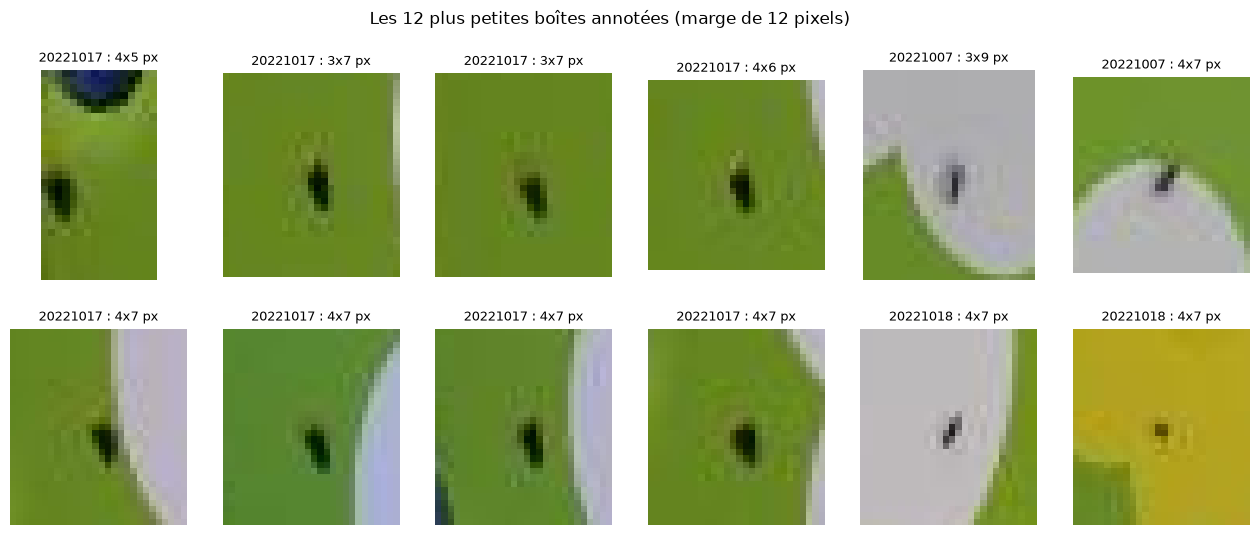

In [27]:
toutes_boites = [(img, b) for img in verite for b in lire_boites(img)]
def aire_boite(b):
    return (b[2] - b[0]) * (b[3] - b[1])

petites = [ib for ib in toutes_boites if aire_boite(ib[1]) < 100]
print(f"{len(toutes_boites)} boîtes annotées, dont {len(petites)} de moins de 100 pixels² ({len(petites) / len(toutes_boites):.0%})")

plus_petites = sorted(toutes_boites, key=lambda ib: aire_boite(ib[1]))[:12]
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for ax, (img, (x1, y1, x2, y2)) in zip(axes.ravel(), plus_petites):
    image = cv2.cvtColor(cv2.imread(str(img)), cv2.COLOR_BGR2RGB)
    m = 12
    ax.imshow(image[max(0, y1 - m):min(TAILLE, y2 + m), max(0, x1 - m):min(TAILLE, x2 + m)], interpolation="nearest")
    ax.set_title(f"{img.name[:8]} : {x2 - x1}x{y2 - y1} px", fontsize=9)
    ax.axis("off")
plt.suptitle("Les 12 plus petites boîtes annotées (marge de 12 pixels)")
plt.show()

13 % des boîtes font moins de 10 × 10 pixels. Les plus petites (3 × 7 pixels) sont des points sombres : on devine un insecte allongé, mais à cette résolution on ne peut pas exclure une saleté, un trou ou une graine. Plusieurs boîtes du 17/10 montrent la même tache au même endroit sur des photos différentes : insecte immobile compté à chaque photo, ou défaut de la plaque annoté par erreur, les images ne permettent pas de trancher. Avec une aire minimale de 40 pixels, la méthode ne peut de toute façon pas détecter ces cas.

Une partie de l'erreur mesurée vient donc peut-être de la vérité terrain. Il faudrait des règles d'annotation écrites (taille minimale, traitement d'une tache immobile) et un même lot annoté par deux personnes : leur accord donnerait le meilleur score atteignable par une méthode automatique.

### 8.2 Ce que je demanderais à l'acquisition

| Problème mesuré | Demande | Effet attendu |
|---|---|---|
| la plaque bouge, la soustraction de fond échoue (6.5) | caméra et plaque fixées rigidement | rendre possible la soustraction de fond |
| ombres des coupelles et des arbres, principale source de fausses détections (5) | éclairage diffus, pas de soleil direct, objets mats | supprimer les zones sombres qui imitent les insectes |
| vis et boutons détectés comme insectes (4, 5) | vis de la couleur de la plaque, ou hors champ | supprimer une fausse détection systématique |
| 13 % des insectes font moins de 10 × 10 pixels (8.1) | résolution telle que le plus petit insecte d'intérêt fasse au moins une quinzaine de pixels de long, sans redimensionnement qui déforme | voir ce qu'on doit compter |
| balance des blancs variable (17/10) | réglages de caméra fixes (exposition, balance des blancs) | un seuil réglé un jour reste valable le lendemain |
| un même insecte compté sur plusieurs photos | cadence adaptée à la question et horodatage précis | suivre un insecte d'une image à l'autre et compter des individus |

## 9. Limites de l'évaluation et conclusion

### Le réglage optimise le comptage, pas la détection

Les paramètres sont choisis pour minimiser la MAE, qui ne regarde que le nombre de taches et peut donc favoriser une compensation entre insectes manqués et fausses détections (6.4). Pour vérifier que ce choix n'est pas la cause du résultat, je refais le réglage en maximisant le F1 des détections, F1 = 2·VP / (2·VP + FP + FN), avec la même grille et la même validation.

In [30]:
debut = time.time()
combinaisons = [(s, a, b) for s in PETITE_GRILLE[0] for a in PETITE_GRILLE[1] for b in PETITE_GRILLE[2]]
bilans = {c: {img: apparier(img, *c) for img in verite} for c in combinaisons}

def f1(c, images):
    vp = sum(bilans[c][img][1] for img in images)
    fp = sum(bilans[c][img][2] for img in images)
    fn = sum(bilans[c][img][3] for img in images)
    return 2 * vp / (2 * vp + fp + fn)

predits_f1, VP, FP, FN = {}, 0, 0, 0
for jour in sorted(journees_gardees):
    autres = [img for j in journees_gardees if j != jour for img in journees_gardees[j]]
    meilleur = max(combinaisons, key=lambda c: f1(c, autres))
    print(f"  ({jour} : réglage choisi pour le F1 = seuil {meilleur[0]}, aire {meilleur[1]}-{meilleur[2]})")
    for img in journees_gardees[jour]:
        k, vp, fp, fn = bilans[meilleur][img]
        predits_f1[img] = k
        VP, FP, FN = VP + vp, FP + fp, FN + fn

r = evaluer(list(verite.values()), [predits_f1[img] for img in verite])
print(f"\nréglé pour le F1 : exact. {r['exactitude']:.2f}  MAE {r['MAE']:.2f}  biais {r['biais']:.2f}  ±1 {r['exact_pm1']:.2f}")
print(f"détections : précision {VP / (VP + FP):.2f}, rappel {VP / (VP + FN):.2f}, F1 {2 * VP / (2 * VP + FP + FN):.2f}")
print(f"temps : {time.time() - debut:.0f} s")

  (20221006 : réglage choisi pour le F1 = seuil 40, aire 10-300)
  (20221007 : réglage choisi pour le F1 = seuil 60, aire 40-300)
  (20221012 : réglage choisi pour le F1 = seuil 60, aire 40-300)
  (20221017 : réglage choisi pour le F1 = seuil 60, aire 40-300)
  (20221018 : réglage choisi pour le F1 = seuil 70, aire 40-300)
  (20221019 : réglage choisi pour le F1 = seuil 60, aire 40-300)
  (20221020 : réglage choisi pour le F1 = seuil 60, aire 40-300)

réglé pour le F1 : exact. 0.17  MAE 1.97  biais 1.09  ±1 0.56
détections : précision 0.35, rappel 0.56, F1 0.43
temps : 43 s


Réglée pour le F1, la méthode trouve un peu plus d'insectes (rappel 0,56 contre 0,46) mais fait beaucoup plus de fausses détections (précision 0,35 contre 0,53), et son comptage se dégrade fortement (MAE 1,97). Le critère de réglage n'est donc pas en cause : avec seulement la luminosité et la taille, on ne sépare pas les insectes des ombres et des vis.

### Autres limites

- **Petites fuites d'information.** Le seuil de 80 de la section 4 a été choisi sur une image du 18/10, ensuite évaluée ; l'histogramme des tailles (6.2) utilise les annotations de toutes les journées et a guidé le choix de la grille. L'effet est sans doute faible, puisque le réglage final est fait en validation une journée de côté.
- **Peu de journées, images corrélées.** Avec 7 journées et des photos très semblables au sein d'une journée, les 1 101 images ne sont pas 1 101 observations indépendantes. Les écarts de quelques centièmes de MAE ne sont pas significatifs ; seules les grandes tendances le sont.
- **Question du biologiste supposée.** La section 7 suppose une comparaison entre journées. Pour une autre question (présence ou absence, individus, temps passé sur une fleur), il faudrait une autre mesure.
- **Vérité terrain imparfaite.** Les plus petites annotations sont douteuses et l'accord entre annotateurs est inconnu.

### Conclusion

**Méthode retenue** : niveaux de gris, seuil à 70, composantes connexes, taches de 40 à 150 pixels ne touchant pas le bord, comptage. Quelques secondes pour 1 101 images sur un portable.

**Évaluation** : mesures de comptage par image (exactitude, MAE, biais, ±1) par journée et au global ; deux références naïves ; validation une journée de côté au lieu du découpage aléatoire de Roboflow ; précision et rappel des détections ; nombre d'insectes par image et par journée.

**Résultats**

| | Exactitude | MAE globale | MAE moyenne des journées | Biais | ±1 |
|---|---|---|---|---|---|
| Toujours 1 | 0,44 | 0,80 | 0,77 | −0,75 | 0,81 |
| Méthode retenue | 0,38 | 0,89 | 1,02 | −0,03 | 0,80 |

- Pas de différence nette avec la référence « toujours 1 » : mieux sur 3 journées sur 7, nettement moins bien sur le 12/10 et le 20/10.
- 46 % des insectes trouvés, une détection sur deux fausse ; le biais quasi nul vient d'une compensation.
- Par journée, le total est faux de −42 % à +159 % et le classement des journées est faux.

**Ce qui ne marche pas** : les ombres et les vis ressemblent trop aux insectes en luminosité et en taille, quel que soit le critère de réglage ; la plaque bouge, ce qui empêche la soustraction de fond ; une partie des insectes annotés fait quelques pixels.

**Suite envisagée**
1. Agir d'abord sur l'acquisition (8.2), probablement le levier le plus efficace.
2. Écrire des règles d'annotation et mesurer l'accord entre annotateurs.
3. Ajouter des critères de forme et de couleur (allongement, contraste local) pour séparer insectes et vis.
4. Si nécessaire, passer à un modèle appris, évalué avec le même protocole pour une comparaison honnête.